# Bank Marketing — Model Tuning

## Objective

This notebook optimizes the HistGradientBoosting candidate selected
during model comparison.

Hyperparameters are selected using stratified cross-validation on the
training set. Average precision is used as the primary selection metric
because the target variable is imbalanced.

The held-out test set remains untouched and will be used only for the
final model evaluation.

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    train_test_split,
    cross_val_predict,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

In [2]:
df = pd.read_csv(
    "../data/raw/bank-full.csv",
    sep=";",
)

X = df.drop(columns=["y", "duration"]).copy()

y = df["y"].map({
    "no": 0,
    "yes": 1,
})

In [3]:
X["previously_contacted"] = (
    X["pdays"] != -1
).astype("int8")

X["pdays"] = X["pdays"].replace(-1, 0)

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

In [5]:
categorical_features = X_train.select_dtypes(
    include=["object", "string"]
).columns.tolist()

numeric_features = [
    "age",
    "balance",
    "day",
    "campaign",
    "pdays",
    "previous",
]

binary_features = [
    "previously_contacted",
]

In [6]:
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median"),
        ),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent"),
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            ),
        ),
    ]
)

In [7]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_transformer,
            numeric_features,
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features,
        ),
        (
            "binary",
            "passthrough",
            binary_features,
        ),
    ]
)

In [8]:
candidate_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor,
        ),
        (
            "classifier",
            HistGradientBoostingClassifier(
                class_weight="balanced",
                random_state=42,
            ),
        ),
    ]
)

In [9]:
parameter_space = {
    "classifier__learning_rate": [
        0.03,
        0.05,
        0.10,
    ],
    "classifier__max_iter": [
        100,
        200,
        300,
    ],
    "classifier__max_leaf_nodes": [
        15,
        31,
        63,
    ],
    "classifier__min_samples_leaf": [
        10,
        20,
        40,
        80,
    ],
    "classifier__l2_regularization": [
        0.0,
        0.1,
        1.0,
        10.0,
    ],
}

In [10]:
cross_validation = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

In [11]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1_score": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
}

In [12]:
randomized_search = RandomizedSearchCV(
    estimator=candidate_pipeline,
    param_distributions=parameter_space,
    n_iter=24,
    scoring=scoring,
    refit="average_precision",
    cv=cross_validation,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    error_score="raise",
    return_train_score=False,
)

In [13]:
randomized_search.fit(
    X_train,
    y_train,
)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__l2_regularization': [0.0, 0.1, ...], 'classifier__learning_rate': [0.03, 0.05, ...], 'classifier__max_iter': [100, 200, ...], 'classifier__max_leaf_nodes': [15, 31, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",24
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","{'accuracy': 'accuracy', 'average_precision': 'average_precision', 'f1_score': 'f1', 'precision': 'precision', ...}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'average_precision'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither 

In [14]:
print(
    "Best cross-validated average precision:",
    round(randomized_search.best_score_, 4),
)

randomized_search.best_params_

Best cross-validated average precision: 0.4505


{'classifier__min_samples_leaf': 10,
 'classifier__max_leaf_nodes': 63,
 'classifier__max_iter': 300,
 'classifier__learning_rate': 0.05,
 'classifier__l2_regularization': 10.0}

In [15]:
search_results = pd.DataFrame(
    randomized_search.cv_results_
)

result_columns = [
    "rank_test_average_precision",
    "mean_test_average_precision",
    "std_test_average_precision",
    "mean_test_roc_auc",
    "mean_test_f1_score",
    "mean_test_precision",
    "mean_test_recall",
    "params",
]

top_search_results = (
    search_results[result_columns]
    .sort_values("rank_test_average_precision")
    .head(10)
)

top_search_results

,rank_test_average_precision,mean_test_average_precision,std_test_average_precision,mean_test_roc_auc,mean_test_f1_score,mean_test_precision,mean_test_recall,params
4,1,0.450477,0.010731,0.797095,0.447319,0.351756,0.614988,"{'classifier__min_samples_leaf': 10, 'classifi..."
9,2,0.448898,0.015303,0.798718,0.452592,0.357639,0.616876,"{'classifier__min_samples_leaf': 10, 'classifi..."
0,3,0.448758,0.010984,0.798827,0.448169,0.348876,0.627040,"{'classifier__min_samples_leaf': 10, 'classifi..."
16,4,0.448275,0.011582,0.796965,0.446506,0.349623,0.618534,"{'classifier__min_samples_leaf': 40, 'classifi..."
19,5,0.447933,0.011814,0.798166,0.451808,0.356402,0.617586,"{'classifier__min_samples_leaf': 10, 'classifi..."
3,6,0.447448,0.012933,0.797861,0.450944,0.355416,0.617350,"{'classifier__min_samples_leaf': 40, 'classifi..."
6,7,0.446500,0.011944,0.797922,0.444195,0.345390,0.622785,"{'classifier__min_samples_leaf': 40, 'classifi..."
22,7,0.446500,0.011944,0.797922,0.444195,0.345390,0.622785,"{'classifier__min_samples_leaf': 40, 'classifi..."
20,9,0.446083,0.013312,0.795097,0.450966,0.356786,0.613570,"{'classifier__min_samples_leaf': 40, 'classifi..."
12,10,0.444800,0.012877,0.797878,0.445179,0.346273,0.623968,"{'classifier__min_samples_leaf': 80, 'classifi..."


## Hyperparameter Tuning Findings

- Randomized search evaluated 24 hyperparameter configurations using five-fold stratified cross-validation, for a total of 120 model fits.
- The best configuration achieved a mean cross-validated average precision of 0.4505, compared with 0.4429 for the initial HistGradientBoosting model.
- The improvement in average precision is modest and should be interpreted together with its cross-validation standard deviation of 0.0107.
- The selected configuration uses a learning rate of 0.05, 300 boosting iterations, 63 maximum leaf nodes, 10 minimum samples per leaf, and L2 regularization of 10.0.
- At the default classification threshold, the selected configuration obtains mean precision of 35.18%, mean recall of 61.50%, and mean F1-score of 0.447.
- The highest-ranked configurations produce similar results, suggesting that model performance is relatively stable across several parameter combinations.
- The test set has not been used during hyperparameter selection.

In [17]:
best_pipeline = randomized_search.best_estimator_

out_of_fold_probabilities = cross_val_predict(
    best_pipeline,
    X_train,
    y_train,
    cv=cross_validation,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

In [18]:
precision_values, recall_values, thresholds = (
    precision_recall_curve(
        y_train,
        out_of_fold_probabilities,
    )
)

f1_values = np.divide(
    2 * precision_values * recall_values,
    precision_values + recall_values,
    out=np.zeros_like(precision_values),
    where=(precision_values + recall_values) > 0,
)

In [19]:
best_threshold_index = np.argmax(
    f1_values[:-1]
)

selected_threshold = thresholds[
    best_threshold_index
]

threshold_summary = pd.Series({
    "selected_threshold": selected_threshold,
    "precision": precision_values[best_threshold_index],
    "recall": recall_values[best_threshold_index],
    "f1_score": f1_values[best_threshold_index],
})

threshold_summary

selected_threshold    0.645058
precision             0.457346
recall                0.515717
f1_score              0.484781
dtype: float64

In [20]:
def calculate_threshold_metrics(threshold):
    predictions = (
        out_of_fold_probabilities >= threshold
    ).astype(int)

    return pd.Series({
        "accuracy": accuracy_score(
            y_train,
            predictions,
        ),
        "precision": precision_score(
            y_train,
            predictions,
            zero_division=0,
        ),
        "recall": recall_score(
            y_train,
            predictions,
            zero_division=0,
        ),
        "f1_score": f1_score(
            y_train,
            predictions,
            zero_division=0,
        ),
        "predicted_positives": predictions.sum(),
    })

In [21]:
threshold_comparison = pd.concat(
    [
        calculate_threshold_metrics(0.5).rename(
            "default_threshold"
        ),
        calculate_threshold_metrics(
            selected_threshold
        ).rename("selected_threshold"),
    ],
    axis=1,
)

threshold_comparison

,default_threshold,selected_threshold
accuracy,0.822108,0.871765
precision,0.351289,0.457346
recall,0.614985,0.515717
f1_score,0.447156,0.484781
predicted_positives,7407.000000,4771.000000


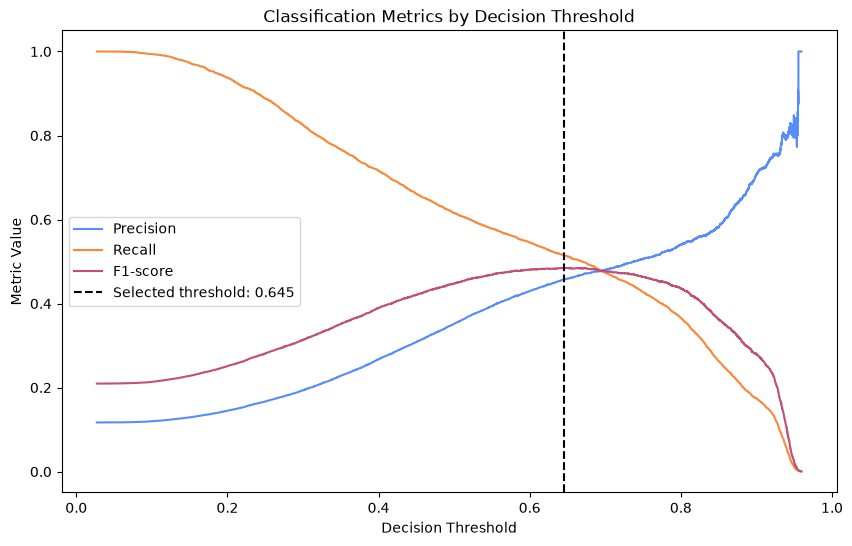

In [22]:
plt.figure(figsize=(10, 6))

plt.plot(
    thresholds,
    precision_values[:-1],
    label="Precision",
)

plt.plot(
    thresholds,
    recall_values[:-1],
    label="Recall",
)

plt.plot(
    thresholds,
    f1_values[:-1],
    label="F1-score",
)

plt.axvline(
    selected_threshold,
    color="black",
    linestyle="--",
    label=f"Selected threshold: {selected_threshold:.3f}",
)

plt.title("Classification Metrics by Decision Threshold")
plt.xlabel("Decision Threshold")
plt.ylabel("Metric Value")
plt.legend()
plt.show()

## Decision Threshold Findings

- The default threshold of 0.5 produces mean out-of-fold precision of 35.13%, recall of 61.50%, and an F1-score of 0.447.
- Maximizing the out-of-fold F1-score selects a decision threshold of approximately 0.645.
- At the selected threshold, precision increases to 45.73% and the F1-score increases to 0.485.
- Recall decreases to 51.57%, reflecting the expected tradeoff between identifying more subscribers and reducing false-positive predictions.
- The selected threshold reduces the number of predicted positive observations from 7,407 to 4,771.
- The threshold was selected exclusively from out-of-fold training predictions. The held-out test set remains untouched.
- A different operational objective could require a different threshold. For example, a campaign prioritizing recall could use a lower threshold, while a campaign with high contact costs could prefer higher precision.